# M4.2 Governance KPIs and anomalies: Keystone Fuel & Market

Reads only committed, sanitized evidence. No tenant connection, so it still runs after the trial ends (2026-11-19).

| Point in time | What it is | File |
|---|---|---|
| Legacy | Access export before the lab (synthetic, as of 2026-10-14) | `data/t0/` |
| **T0** | Tenant after the HR load, before roles (2026-10-27) | `evidence/M1.4/snapshot_T0_*` |
| **T1** | Tenant after access packages and reviews (2026-11-11) | `evidence/M4.1/snapshot_T1_*` |

Outputs: `reports/m4-kpis.csv`, `reports/m4-anomalies.csv`, `reports/img/m4-*.png`. M4.3 turns them into the trend report.

## 1. Setup and load

In [19]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EV, REPORTS = ROOT / "evidence", ROOT / "reports"
IMG = REPORTS / "img"
IMG.mkdir(parents=True, exist_ok=True)

FILES = {
    "legacy_hr":  ROOT / "data/t0/hr_feed.csv",
    "legacy_ent": ROOT / "data/t0/entitlement_assignments.csv",
    "t0":         EV / "M1.4/snapshot_T0_2026-10-27_sanitized.csv",
    "t0_runs":    EV / "M1.4/snapshot_T0_2026-10-27_lcw_runs_sanitized.csv",
    "t1":         EV / "M4.1/snapshot_T1_2026-11-11_sanitized.csv",
    "t1_runs":    EV / "M4.1/snapshot_T1_2026-11-11_lcw_runs_sanitized.csv",
    "reviews":    EV / "M3/access_review_decisions_2026-11-09_1950.csv",
}
# Everything as text; blanks as "" (not NaN) so string tests behave the same on every pandas version
D = {k: pd.read_csv(p, dtype=str, keep_default_na=False) for k, p in FILES.items()}
for k, df in D.items():
    print(f"{k:<11} {len(df):>5} rows  {FILES[k].relative_to(ROOT).as_posix()}")

legacy_hr     300 rows  data/t0/hr_feed.csv
legacy_ent   1641 rows  data/t0/entitlement_assignments.csv
t0            278 rows  evidence/M1.4/snapshot_T0_2026-10-27_sanitized.csv
t0_runs         5 rows  evidence/M1.4/snapshot_T0_2026-10-27_lcw_runs_sanitized.csv
t1            277 rows  evidence/M4.1/snapshot_T1_2026-11-11_sanitized.csv
t1_runs        11 rows  evidence/M4.1/snapshot_T1_2026-11-11_lcw_runs_sanitized.csv
reviews       288 rows  evidence/M3/access_review_decisions_2026-11-09_1950.csv


In [20]:
def utc(s):
    """ISO text -> UTC timestamp; blank -> NaT."""
    return pd.to_datetime(s, utc=True, errors="coerce")

def split(cell):
    """'BR-01;BR-02' -> {'BR-01', 'BR-02'}; '' -> empty set."""
    return set(x for x in str(cell).split(";") if x)

KPIS = []   # one row per KPI -> reports/m4-kpis.csv
def kpi(area, name, t0, t1, unit, note=""):
    KPIS.append(dict(area=area, kpi=name, t0=t0, t1=t1, unit=unit, note=note))

t0, t1 = D["t0"], D["t1"]
print("pandas", pd.__version__)

pandas 3.0.6


## 2. Population T0 → T1

Every number the report uses about *who* is in the tenant. HR is authoritative; the snapshots only hold HR-sourced accounts.

In [21]:
def population(df):
    enabled = df["account_enabled"] == "True"
    return {
        "HR accounts":             len(df),
        "enabled":                 int(enabled.sum()),
        "leave date set":          int((df["leave_datetime_utc"] != "").sum()),
        "enabled, in a BR group":  int((enabled & (df["birthright_groups"] != "")).sum()),
        "enabled, no BR group":    int((enabled & (df["birthright_groups"] == "")).sum()),
        "no manager in Entra":     int((df["manager_employee_id"] == "").sum()),
    }
pop = pd.DataFrame({"T0 2026-10-27": population(t0), "T1 2026-11-11": population(t1)})
pop["change"] = pop.iloc[:, 1] - pop.iloc[:, 0]
print(pop.to_string())
for name, row in pop.iterrows():
    kpi("Population", name, row.iloc[0], row.iloc[1], "accounts")

                        T0 2026-10-27  T1 2026-11-11  change
HR accounts                       278            277      -1
enabled                           275            277       2
leave date set                      1              0      -1
enabled, in a BR group            275            277       2
enabled, no BR group                0              0       0
no manager in Entra                57             57       0


In [22]:
# Joiners, leavers, movers between the two snapshots (by employee ID)
a = t0.set_index("employee_id"); b = t1.set_index("employee_id")
joiners = sorted(set(b.index) - set(a.index))
leavers = sorted(set(a.index) - set(b.index))
both = sorted(set(a.index) & set(b.index))
changes = []
for e in both:
    for col in ["department", "job_title", "account_enabled"]:
        if a.at[e, col] != b.at[e, col]:
            changes.append(dict(employee_id=e, name=b.at[e, "display_name"], field=col,
                                t0=a.at[e, col], t1=b.at[e, col]))
changes = pd.DataFrame(changes)
print("Joiners (in T1 only):", joiners)
print("Leavers (in T0 only):", leavers, "-> deleted by JML-L2")
print(changes.to_string(index=False))

Joiners (in T1 only): []
Leavers (in T0 only): ['E00010'] -> deleted by JML-L2
employee_id            name           field               t0              t1
     E00006  Cameron Tanaka       job_title       Shift Lead Store Associate
     E00013     Alex Larsen       job_title  Store Associate      Shift Lead
     E00034   Finley Moreau      department Store Operations Fuel Operations
     E00034   Finley Moreau       job_title  Store Associate Fuel Technician
     E00301 Avery Lindqvist account_enabled            False            True
     E00302    Riley Okafor account_enabled            False            True


## 3. Access through roles: legacy vs T1

The 10 title-based entitlements (stand-in groups `ENT-*` in the tenant). A holder is **inside the rule** if department + title match the role that grants it (role catalog, M2.3). Legacy = who actually held them before the lab; T1 = who holds them now.

In [23]:
# Role rules = docs/access-packages.md section 3 (department, titles, what the package grants)
RULES = {
    "BUS-01": ("Store Operations", {"Store Associate", "Shift Lead"}, ["POS-Cashier"]),
    "BUS-02": ("Store Operations", {"Store Manager"}, ["POS-Manager", "Inventory-Approver", "Scheduling-Admin", "SafeCount-Operator"]),
    "ADD-01": ("Store Operations", {"Shift Lead"}, ["POS-Refunds"]),
    "BUS-03": ("Fuel Operations", {"Fuel Technician"}, ["FuelPricing-View", "TankMonitor-Operator"]),
    "BUS-04": ("Fuel Operations", {"Fuel Operations Manager"}, ["FuelPricing-Edit", "TankMonitor-Admin"]),
}
APP_ROLE = {"BUS-02": "StoreOps.StoreManager", "ADD-01": "StoreOps.ShiftLead",
            "ADD-06": "StoreOps.CashOffice", "ADD-07": "StoreOps.Admin"}
ENTS = [e for _, _, ents in RULES.values() for e in ents]

def allowed(dept, title, ent):
    return any(dept == d and title in titles and ent in ents for d, titles, ents in RULES.values())

# Legacy: active HR people and their direct entitlement grants
lhr = D["legacy_hr"][D["legacy_hr"]["status"] == "Active"].set_index("upn")
lent = D["legacy_ent"][D["legacy_ent"]["entitlement"].isin(ENTS) & D["legacy_ent"]["upn"].isin(lhr.index)].copy()
lent["inside_rule"] = [allowed(lhr.at[u, "department"], lhr.at[u, "job_title"], e)
                       for u, e in zip(lent["upn"], lent["entitlement"])]

# T1: enabled accounts and their ENT- groups
t1_ent = t1[t1["account_enabled"] == "True"][["employee_id", "department", "job_title", "ent_groups"]].copy()
t1_ent["entitlement"] = t1_ent["ent_groups"].map(lambda c: sorted(x.removeprefix("ENT-") for x in split(c)))
t1_ent = t1_ent.explode("entitlement").dropna(subset=["entitlement"])
t1_ent["inside_rule"] = [allowed(d, t, e) for d, t, e in zip(t1_ent["department"], t1_ent["job_title"], t1_ent["entitlement"])]

cmp = pd.DataFrame({
    "legacy_holders": lent.groupby("entitlement").size(),
    "legacy_outside_rule": lent[~lent["inside_rule"]].groupby("entitlement").size(),
    "t1_holders": t1_ent.groupby("entitlement").size(),
    "t1_outside_rule": t1_ent[~t1_ent["inside_rule"]].groupby("entitlement").size(),
}).reindex(ENTS).fillna(0).astype(int)
cmp.loc["TOTAL"] = cmp.sum()
print(cmp.to_string())
print()
print("Legacy grant source for these entitlements:", lent["grant_source"].value_counts().to_dict())

                      legacy_holders  legacy_outside_rule  t1_holders  t1_outside_rule
entitlement                                                                           
POS-Cashier                      117                   11         105                0
POS-Manager                       64                   12          52                0
Inventory-Approver                64                   12          52                0
Scheduling-Admin                  65                   13          52                0
SafeCount-Operator                66                   14          52                0
POS-Refunds                       65                    5          60                0
FuelPricing-View                   9                    3           7                0
TankMonitor-Operator               7                    1           7                0
FuelPricing-Edit                  11                    0          11                0
TankMonitor-Admin                 18       

In [24]:
tot = cmp.loc["TOTAL"]
legacy_pct_out = round(100 * tot["legacy_outside_rule"] / tot["legacy_holders"], 1)
legacy_manual = int((lent["grant_source"] != "Birthright").sum())
pkg_people = int((t1["access_packages"] != "").sum())
pkg_assign = int(t1["access_packages"].map(lambda c: len(split(c))).sum())
print(f"Legacy: {tot['legacy_holders']} grants, {tot['legacy_outside_rule']} outside the rule ({legacy_pct_out}%), "
      f"{legacy_manual} granted by request or by hand")
print(f"T1:     {tot['t1_holders']} grants, {tot['t1_outside_rule']} outside the rule, all delivered by an access package")
print(f"T1 packages: {pkg_people} people, {pkg_assign} assignments")
kpi("Roles", "title entitlement grants", int(tot["legacy_holders"]), int(tot["t1_holders"]), "grants", "legacy = data/t0 export; T1 = ENT- groups")
kpi("Roles", "grants outside the role rule", int(tot["legacy_outside_rule"]), int(tot["t1_outside_rule"]), "grants")
kpi("Roles", "grants outside the role rule %", legacy_pct_out, 0.0, "%")
kpi("Roles", "grants made by request or by hand", legacy_manual, 0, "grants", "T1: every grant comes from an automatic or requested package")
kpi("Roles", "people with an access package", 0, pkg_people, "people", "T0 had no packages (built 2026-10-28)")
kpi("Roles", "access package assignments", 0, pkg_assign, "assignments")

Legacy: 486 grants, 78 outside the rule (16.0%), 224 granted by request or by hand
T1:     409 grants, 0 outside the rule, all delivered by an access package
T1 packages: 177 people, 241 assignments


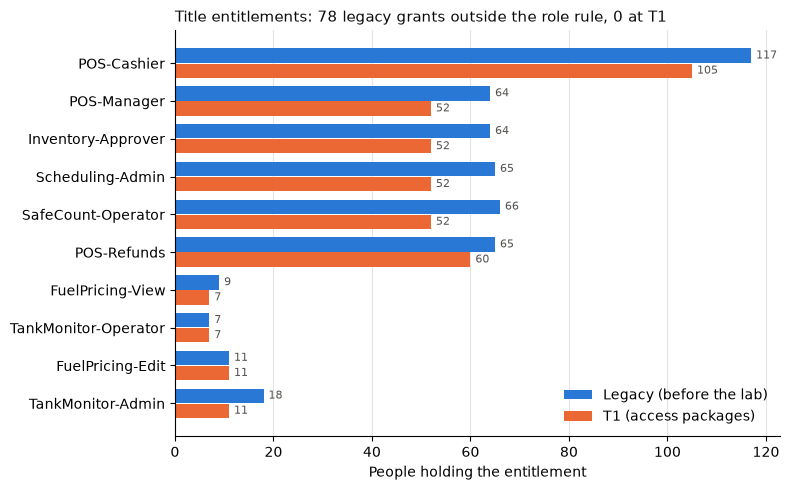

In [25]:
# Chart: grants per entitlement, legacy vs T1 (one axis, two series, direct labels)
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plot = cmp.drop(index="TOTAL")
y = range(len(plot))
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([i - 0.2 for i in y], plot["legacy_holders"], height=0.38, color=BLUE, label="Legacy (before the lab)")
ax.barh([i + 0.2 for i in y], plot["t1_holders"], height=0.38, color=ORANGE, label="T1 (access packages)")
for i, (l, t) in enumerate(zip(plot["legacy_holders"], plot["t1_holders"])):
    ax.text(l + 1, i - 0.2, str(l), va="center", fontsize=8, color=MUTED)
    ax.text(t + 1, i + 0.2, str(t), va="center", fontsize=8, color=MUTED)
ax.set_yticks(list(y), plot.index); ax.invert_yaxis()
ax.set_xlabel("People holding the entitlement")
ax.set_title(f"Title entitlements: {tot['legacy_outside_rule']} legacy grants outside the role rule, {tot['t1_outside_rule']} at T1",
             loc="left", fontsize=11, color=INK)
for s in ["top", "right"]: ax.spines[s].set_visible(False)
ax.grid(axis="x", color="#e5e4df", linewidth=0.8); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(IMG / "m4-entitlements-legacy-vs-t1.png", dpi=150)
plt.show()

## 4. Drift: access that no package explains

Drift = an `ENT-` group or StoreOps Portal role a person holds **without** holding the package that grants it (someone added it by hand), or an automatic package that HR data no longer supports (mover residual). The -Verify scripts check counts per package; this checks every person.

In [26]:
def drift(df):
    """Return one row per unexplained holding."""
    found = []
    for _, r in df[df["account_enabled"] == "True"].iterrows():
        pkgs = split(r["access_packages"])
        want_ent = {f"ENT-{e}" for p in pkgs if p in RULES for e in RULES[p][2]}
        want_role = {APP_ROLE[p] for p in pkgs if p in APP_ROLE}
        for g in sorted(split(r["ent_groups"]) - want_ent):
            found.append((r["employee_id"], r["display_name"], "group without package", g))
        for role in sorted(split(r["storeops_roles_direct"]) - want_role):
            found.append((r["employee_id"], r["display_name"], "app role without package", role))
        for p in sorted(pkgs & RULES.keys()):
            d, titles, _ = RULES[p]
            if not (r["department"] == d and r["job_title"] in titles):
                found.append((r["employee_id"], r["display_name"], "package HR no longer supports", p))
    return pd.DataFrame(found, columns=["employee_id", "name", "type", "item"])

dr = drift(t1)
print(f"Drift at T1: {len(dr)} item(s)")
print(dr.to_string(index=False) if len(dr) else "(none)")
kpi("Drift", "access not explained by a package", "", len(dr), "items", "T0 had no packages to compare against")

Drift at T1: 0 item(s)
(none)


**A check that passes on zero items isn't a check.** Plant two known problems in a *copy* of T1 and confirm the same function finds exactly those two. The evidence file is not changed.

In [27]:
test = t1.copy()
i6 = test.index[test["employee_id"] == "E00006"][0]   # Cameron: demoted to Store Associate on 10-29
i2 = test.index[test["employee_id"] == "E00002"][0]   # Kai Achebe: Fuel Operations Manager
test.at[i6, "ent_groups"] = test.at[i6, "ent_groups"] + ";ENT-POS-Refunds"      # refunds added by hand
test.at[i2, "storeops_roles_direct"] = "StoreOps.CashOffice"                    # Cash Office with no ADD-06
neg = drift(test)
print(neg.to_string(index=False))
print("Negative test:", "PASS" if len(neg) == 2 else f"FAIL ({len(neg)} found, expected 2)")

employee_id           name                     type                item
     E00002     Kai Achebe app role without package StoreOps.CashOffice
     E00006 Cameron Tanaka    group without package     ENT-POS-Refunds
Negative test: PASS


## 5. Joiner, mover, leaver: did the workflows act, and how fast?

Workflow run history = portal export (Graph only returns the last 7 days). **Count failures by failed tasks, not by run status:** a run whose task failed shows `completedWithErrors`.

In [28]:
runs = D["t1_runs"].copy()
runs["tasks_failed"] = runs["tasks_failed"].astype(int)
runs["started"] = utc(runs["started_utc"])
runs["completed"] = utc(runs["completed_utc"])
show = runs[["workflow", "employee_id", "execution_type", "started_utc", "status", "tasks_total", "tasks_failed"]]
print(show.to_string(index=False))
failed = runs[runs["tasks_failed"] > 0]
print(f"\nRuns: {len(runs)} | with a failed task: {len(failed)} ({100 * len(failed) / len(runs):.0f}%) | "
      f"status 'failed': {(runs['status'] == 'failed').sum()}")

                         workflow employee_id execution_type          started_utc              status tasks_total  tasks_failed
   JML-J1 Pre-hire TAP to manager      E00302      scheduled 2026-10-25T20:37:50Z completedWithErrors           1             1
   JML-J1 Pre-hire TAP to manager      E00301      scheduled 2026-10-25T20:37:50Z           completed           1             0
         JML-M1 Department change      E00004      scheduled 2026-10-27T13:37:50Z           completed           2             0
         JML-L1 Last day offboard      E00010      scheduled 2026-10-27T14:37:50Z           completed           4             0
         JML-L1 Last day offboard      E00010       onDemand 2026-10-27T15:10:15Z           completed           5             0
            JML-J2 Day one enable      E00301      scheduled 2026-10-31T07:37:00Z           completed           1             0
            JML-J2 Day one enable      E00302      scheduled 2026-10-31T07:37:00Z           completed   

In [29]:
# When was each failure noticed? (not in any export: from the evidence trail)
NOTICED = {  # (workflow prefix, employee) -> (date noticed, how, evidence)
    ("JML-J1", "E00302"): ("2026-10-25", "read the run while testing", "evidence/M1.3/03-j1-riley-failed-task.png"),
    ("JML-M1", "E00034"): ("2026-11-12", "found while building the T1 run file", "evidence/M4.1/01-m1-finley-failed-task.png"),
}
rows = []
for _, r in failed.iterrows():
    when, how, ev = NOTICED[(r["workflow"][:6], r["employee_id"])]
    days = (pd.Timestamp(when, tz="UTC") - r["started"].normalize()).days
    rows.append(dict(workflow=r["workflow"], employee_id=r["employee_id"], failed_task=r["failed_tasks"],
                     run_utc=r["started_utc"][:16], noticed=when, days_unnoticed=days, how=how))
fails = pd.DataFrame(rows)
print(fails.to_string(index=False))
kpi("JML", "workflow runs", len(D["t0_runs"]), len(runs), "runs", "T1 = all runs to date (portal history)")
kpi("JML", "runs with a failed task", int((D["t0_runs"]["tasks_failed"].astype(int) > 0).sum()), len(failed), "runs")
kpi("JML", "longest a failed run went unnoticed", "", int(fails["days_unnoticed"].max()), "days", "no alert on failed runs")

                      workflow employee_id                                          failed_task          run_utc    noticed  days_unnoticed                                  how
JML-J1 Pre-hire TAP to manager      E00302                          Generate TAP and Send Email 2026-10-25T20:37 2026-10-25               0           read the run while testing
      JML-M1 Department change      E00034 (not in portal export: see Workflow history > Tasks) 2026-11-03T16:37 2026-11-12               9 found while building the T1 run file


In [30]:
# Time from trigger to action, per scenario
def first_run(wf, emp):
    r = runs[runs["workflow"].str.startswith(wf) & (runs["employee_id"] == emp) & (runs["execution_type"] == "scheduled")]
    return r.iloc[0]

t1i, t0i = t1.set_index("employee_id"), t0.set_index("employee_id")
FINLEY_HR_LOAD = pd.Timestamp("2026-11-03T16:06:00Z")   # docs/access-packages.md 10.4 (~11:06 ET); load report not committed
timing = [
    ("Joiner enabled (J2)", "E00301", pd.Timestamp(t1i.at["E00301", "hire_datetime_utc"]), first_run("JML-J2", "E00301")["completed"], "hire time 03:00 ET", "same day"),
    ("Joiner enabled (J2)", "E00302", pd.Timestamp(t1i.at["E00302", "hire_datetime_utc"]), first_run("JML-J2", "E00302")["completed"], "hire time 03:00 ET", "same day"),
    ("Leaver disabled (L1)", "E00010", pd.Timestamp(t0i.at["E00010", "leave_datetime_utc"]), first_run("JML-L1", "E00010")["completed"], "leave time 23:00 ET", "same day (PCI 8.2.5)"),
    ("Leaver deleted (L2)", "E00010", pd.Timestamp(t0i.at["E00010", "leave_datetime_utc"]) + pd.Timedelta(7, "D"), first_run("JML-L2", "E00010")["completed"], "leave + 7 days", "within 1 day"),
    ("Mover PCI removed (M2)", "E00034", FINLEY_HR_LOAD, first_run("JML-M2", "E00034")["completed"], "HR load of the move", "next hourly run"),
]
tm = pd.DataFrame(timing, columns=["control", "employee_id", "trigger_utc", "done_utc", "trigger", "target"])
tm["minutes"] = ((tm["done_utc"] - tm["trigger_utc"]).dt.total_seconds() / 60).round().astype(int)
tm["hours"] = (tm["minutes"] / 60).round(1)
print(tm[["control", "employee_id", "trigger", "minutes", "hours", "target"]].to_string(index=False))
for _, r in tm.drop_duplicates("control").iterrows():
    kpi("JML", f"{r['control']} minutes after trigger", "", int(r["minutes"]), "minutes", f"{r['employee_id']}, target {r['target']}")

               control employee_id             trigger  minutes  hours               target
   Joiner enabled (J2)      E00301  hire time 03:00 ET       37    0.6             same day
   Joiner enabled (J2)      E00302  hire time 03:00 ET       37    0.6             same day
  Leaver disabled (L1)      E00010 leave time 23:00 ET      698   11.6 same day (PCI 8.2.5)
   Leaver deleted (L2)      E00010      leave + 7 days       37    0.6         within 1 day
Mover PCI removed (M2)      E00034 HR load of the move       32    0.5      next hourly run


Logan's 11.6 h is **not** workflow lag: HR entered his termination the morning *after* his last day (lab deviation, `docs/lab-environment.md`), and L1 caught up on its next run. The control's speed is bounded by the hourly workflow cycle (J2 37 min, M2 32 min); its real exposure is bounded by **when HR enters the data**.

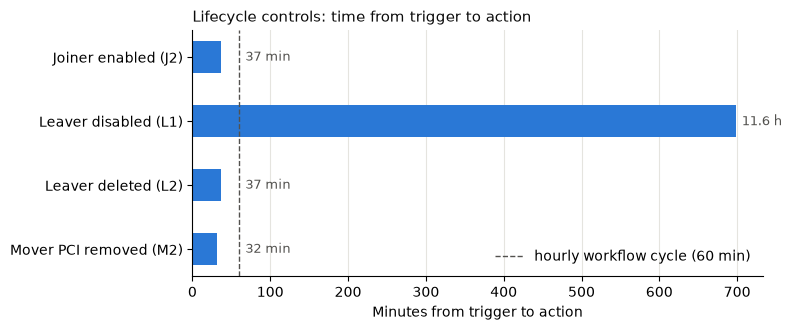

In [31]:
# Chart: minutes from trigger to action (one series; the 60-min line = hourly workflow cycle)
c = tm.drop_duplicates("control").iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(c["control"], c["minutes"], height=0.5, color=BLUE)
for i, (m, h) in enumerate(zip(c["minutes"], c["hours"])):
    ax.text(max(m, 60) + 8, i, f"{m} min" if m < 120 else f"{h} h", va="center", fontsize=9, color=MUTED)
ax.axvline(60, color=MUTED, linestyle="--", linewidth=1, label="hourly workflow cycle (60 min)")
ax.legend(frameon=False, loc="lower right")
ax.set_xlabel("Minutes from trigger to action")
ax.set_title("Lifecycle controls: time from trigger to action", loc="left", fontsize=11, color=INK)
for s in ["top", "right"]: ax.spines[s].set_visible(False)
ax.grid(axis="x", color="#e5e4df", linewidth=0.8); ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(IMG / "m4-jml-time-to-action.png", dpi=150)
plt.show()

In [32]:
# JML-M1 "Remove all access package assignments": has it ever removed anything?
m1 = runs[runs["workflow"].str.startswith("JML-M1")]
held_before = {"E00004": "none (T0 2026-10-27: no packages existed yet)",
               "E00034": "BUS-01, ADD-06 (evidence/M2.5/person_access_before_move_*)"}
for _, r in m1.iterrows():
    print(f"{r['employee_id']} {r['started_utc'][:10]}  packages held: {held_before[r['employee_id']]:<55} "
          f"failed tasks: {r['tasks_failed']}")
effective = 0   # Rowan had nothing to remove; Finley's task failed (removals came from BUS-01 auto policy + JML-M2)
print(f"\nM1 package removal actually removed something: {effective} of {len(m1)} runs")
kpi("JML", "M1 package-removal runs that removed something", "", f"{effective} of {len(m1)}", "runs",
    "Finley: 'Custom assignment schedule is prevented by policy'")

E00004 2026-10-27  packages held: none (T0 2026-10-27: no packages existed yet)           failed tasks: 0
E00034 2026-11-03  packages held: BUS-01, ADD-06 (evidence/M2.5/person_access_before_move_*) failed tasks: 1

M1 package removal actually removed something: 0 of 2 runs


## 6. Access reviews (M3 campaign, November 2026)

Decision file read back after the reviews ended. R2 counts the **final** decision (stage 2). Removal is checked in the T1 snapshot, not taken from the review's status.

In [33]:
rv = D["reviews"].copy()
rv["person"] = rv["employee_id"].where(rv["employee_id"] != "", rv["name"])
final = rv[(rv["review"] != "R2") | (rv["stage"] == "2")]
rec = []
for name, g in final.groupby("review"):
    decided = g["decision"].isin(["Approve", "Deny"])
    with_reco = g[decided & g["recommendation"].isin(["Approve", "Deny"])]
    rec.append(dict(review=name, in_scope=g["person"].nunique(), decided=int(decided.sum()),
                    completion_pct=round(100 * decided.sum() / len(g), 1),
                    denied=int((g["decision"] == "Deny").sum()),
                    agreed_with_reco=f"{int((with_reco['decision'] == with_reco['recommendation']).sum())} of {len(with_reco)}",
                    applied_ok=int((g["apply_result"] == "AppliedSuccessfully").sum())))
rs = pd.DataFrame(rec)
print(rs.to_string(index=False))
print("\nApply results:", final["apply_result"].value_counts().to_dict())

review  in_scope  decided  completion_pct  denied agreed_with_reco  applied_ok
    R1         5        5           100.0       1           1 of 5           0
    R2         3        3           100.0       1           0 of 0           0
    R3       277        2             0.7       0           2 of 2           0

Apply results: {'New': 280, 'AppliedWithUnknownFailure': 5}


In [34]:
# Every Deny: is the access actually gone at T1?
PKG_OF = {"R1": "ADD-06", "R2": "ADD-07"}
denies = final[(final["decision"] == "Deny") & final["review"].isin(PKG_OF)]
out = []
for _, r in denies.iterrows():
    row = t1i.loc[r["employee_id"]]
    gone = PKG_OF[r["review"]] not in split(row["access_packages"]) and APP_ROLE[PKG_OF[r["review"]]] not in split(row["storeops_roles_direct"])
    out.append(dict(review=r["review"], employee_id=r["employee_id"], name=r["name"], removed_by_review=r["apply_result"] == "AppliedSuccessfully",
                    gone_at_T1=gone, how="removed by hand 2026-11-10 01:08 UTC (evidence/M3/07-manual-remediation.png)"))
dn = pd.DataFrame(out)
print(dn.to_string(index=False))
kpi("Reviews", "R1+R2 decisions made", "", int(rs.loc[rs.review.isin(["R1", "R2"]), "decided"].sum()), "decisions", "8 people in scope")
kpi("Reviews", "R1+R2 denies", "", len(dn), "denies")
kpi("Reviews", "denies removed by the review itself", "", f"{int(dn['removed_by_review'].sum())} of {len(dn)}", "denies", "AppliedWithUnknownFailure / New")
kpi("Reviews", "denies removed at T1 (any route)", "", f"{int(dn['gone_at_T1'].sum())} of {len(dn)}", "denies", "manual remediation ~17 h after close")
kpi("Reviews", "R3 inactive review completion %", "", float(rs.loc[rs.review == "R3", "completion_pct"].iloc[0]), "%", "275 of 277 not reviewed: lab artifact, auto-apply off")

review employee_id           name  removed_by_review  gone_at_T1                                                                          how
    R1      E00070 Avery Castillo              False        True removed by hand 2026-11-10 01:08 UTC (evidence/M3/07-manual-remediation.png)
    R2      E00015   Kai Kowalski              False        True removed by hand 2026-11-10 01:08 UTC (evidence/M3/07-manual-remediation.png)


## 7. Anomalies at T1

Each rule runs on the T1 snapshot. `lab_artifact = True` means the result comes from how the lab was built, not from a control gap; the report must say so instead of presenting it as a finding.

In [35]:
en = t1[t1["account_enabled"] == "True"]
by_id = en.set_index("employee_id")
ANOM = []
def anomaly(aid, rule, hits, lab_artifact=False, note=""):
    ids = list(hits["employee_id"]) if len(hits) and "employee_id" in hits else []
    ex = "; ".join(f"{e} {by_id.at[e, 'display_name']}" for e in ids[:5]) if ids else ", ".join(map(str, list(hits.index)[:5]))
    ANOM.append(dict(id=aid, rule=rule, count=len(hits), examples=ex, lab_artifact=lab_artifact, note=note))

# A1 title in a department other than the one that owns that title
home = en.groupby("job_title")["department"].agg(lambda s: s.value_counts().index[0])
anomaly("A1", "Job title outside its home department", en[en["department"] != en["job_title"].map(home)],
        note="title rules must check department too")
# A2 PCI Cash Office held by someone who is not a Store Manager
anomaly("A2", "Cash Office (ADD-06) held by a non-Store Manager",
        en[en["access_packages"].map(lambda c: "ADD-06" in split(c)) & (en["job_title"] != "Store Manager")],
        note="approved in R1 as an exception")
# A3/A4 store staffing: stores with no Store Manager or more than one
stores = en[en["office_location"].str.startswith("Store-")]
sm = stores[stores["job_title"] == "Store Manager"].groupby("office_location").size()
sm = sm.reindex(sorted(stores["office_location"].unique()), fill_value=0)
anomaly("A3", "Store with no Store Manager", sm[sm == 0].to_frame("n"), note="nobody to approve or review store access")
anomaly("A4", "Store with 3 or more Store Managers", sm[sm >= 3].to_frame("n"),
        note=f"{int((sm == 2).sum())} stores have 2; max {int(sm.max())}")
# A5 no manager in Entra
anomaly("A5", "No manager in Entra", en[en["manager_employee_id"] == ""],
        note="breaks manager-based controls: J1 TAP, R2 stage 1, R3, ADD-06 stage 1")
# A6 Store Manager whose manager is lower in the store hierarchy
LEVEL = {"Store Associate": 1, "Shift Lead": 2, "Store Manager": 3}
mgr_title = en["manager_employee_id"].map(by_id["job_title"])
anomaly("A6", "Store Manager reports to a Shift Lead or Store Associate",
        en[(en["job_title"] == "Store Manager") & (mgr_title.map(LEVEL).fillna(9) < 3)],
        note="HR reporting lines inverted; M1.1 counted 29 in the T0 HR file")
# A7 dormant
anomaly("A7", "No sign-in recorded (dormant)", en[en["last_signin_utc"] == ""], lab_artifact=True,
        note="synthetic users never sign in")
# A8 failed workflow tasks
anomaly("A8", "Workflow run with a failed task", failed[["employee_id"]], note="no alerting on failed runs")
# A9 drift
anomaly("A9", "Access not explained by a package", dr)

an = pd.DataFrame(ANOM)
print(an[["id", "rule", "count", "lab_artifact", "examples"]].to_string(index=False))

id                                                     rule  count  lab_artifact                                                                                                    examples
A1                    Job title outside its home department      1         False                                                                                       E00004 Rowan Kowalski
A2         Cash Office (ADD-06) held by a non-Store Manager      1         False                                                                                        E00032 Jamie Ivanova
A3                              Store with no Store Manager      9         False                                                       Store-005, Store-006, Store-011, Store-016, Store-019
A4                      Store with 3 or more Store Managers      2         False                                                                                        Store-031, Store-035
A5                                      No manager in E

## 8. Save outputs for M4.3

In [36]:
k = pd.DataFrame(KPIS)
k.to_csv(REPORTS / "m4-kpis.csv", index=False)
an.to_csv(REPORTS / "m4-anomalies.csv", index=False)
print(f"{len(k)} KPIs  -> reports/m4-kpis.csv")
print(f"{len(an)} anomaly rules -> reports/m4-anomalies.csv")
print("charts:", sorted(p.name for p in IMG.glob("m4-*.png")))
# Leak check: no object IDs / GUIDs in anything this notebook wrote
import re
guid = re.compile(r"[0-9a-f]{8}-[0-9a-f]{4}-")
hits = sum(len(guid.findall((REPORTS / f).read_text())) for f in ["m4-kpis.csv", "m4-anomalies.csv"])
print("GUIDs in outputs:", hits)

26 KPIs  -> reports/m4-kpis.csv
9 anomaly rules -> reports/m4-anomalies.csv
charts: ['m4-entitlements-legacy-vs-t1.png', 'm4-jml-time-to-action.png']
GUIDs in outputs: 0
